# Payroll forecasts after a shock
Sebastian Jaramillo

My doctoral assignment predicted six-month employment growth of 0.182 in 100 log points and estimated a March 2020 variance multiplier of 103.55. The assignment left one question open. How would interpolation compare if it also forecast six months? This notebook reconstructs the scorecards from public forecast records and checks the original forecast against the BLS release. [Protocol](../docs/protocol.md) · [Source records](../data/README.md)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from payroll_volatility.study import score_forecasts
root = next(p for p in (Path.cwd(), *Path.cwd().parents, Path.cwd() / 'project7') if (p / 'results/volatility_percentiles.csv').is_file())
res = root / 'results'
original = pd.read_csv(root / 'data/coursework.csv').set_index('quantity')
f = pd.read_csv(res / 'forecasts.csv')
ref = pd.read_csv(res / 'reference.csv').set_index('treatment')
display(original.drop(columns='cell_id').round(4))

,p025,p05,median,mean,p95,p975,unit
quantity,,,,,,,
march_variance_multiplier,79.7161,NaN,103.5539,104.5119,NaN,134.9603,covariance multiplier
six_month_payroll_growth,-0.9879,-0.7806,0.1820,0.1937,1.1018,1.3222,100 times log change


## What happened between March and September 2026?
Compare the course and refitted medians with observed growth. The two BLS payroll levels come from the same September release vintage. Use the forecasting workbook's March level when converting the archived median to a number of jobs.

In [2]:
levels = pd.read_csv(root / 'data/september_release.csv').seasonally_adjusted_payroll_thousands.to_numpy()
actual = levels[1] - levels[0]
log_growth = 100 * np.log(levels[1] / levels[0])
archived = original.at['six_month_payroll_growth', 'median']
comparison = ref[['median_log', 'median']].copy()
comparison.loc['Coursework'] = [archived, ref.origin_payroll.iloc[0] * np.expm1(archived / 100)]
comparison['median_error_thousands'] = comparison['median'] - actual
print(f'Observed gain: {actual:,.0f} thousand jobs ({log_growth:.4f} log points)')
display(comparison.round(3))

Observed gain: 394 thousand jobs (0.2480 log points)


,median_log,median,median_error_thousands
treatment,,,
Observed,0.331,525.539,131.539
Interpolated,0.223,354.317,-39.683
Temporary volatility,0.198,314.635,-79.365
Coursework,0.182,288.957,-105.043


## Did the model recover the scale of the shock?
The multiplier applies to variance. The standard deviation of a shock grows with its square root. The shaded band reflects uncertainty about the March multiplier. The dates and the monthly decay are fixed.

,multiplier
percentile,
2.5,78.806
50.0,103.675
97.5,136.859


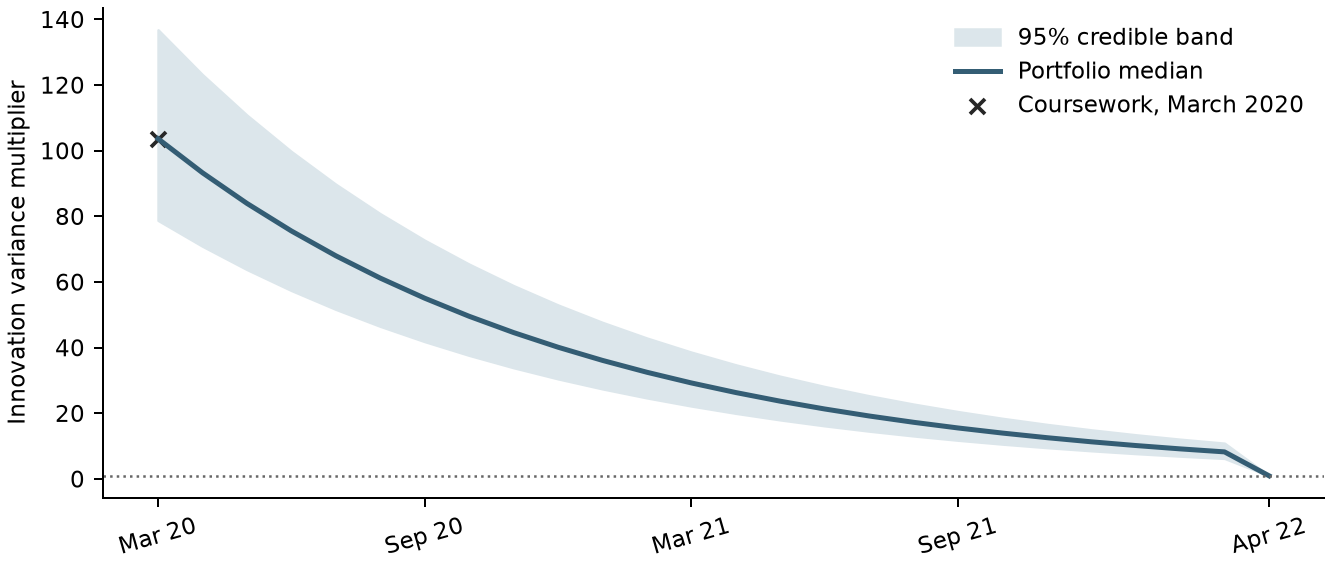

In [3]:
gamma = pd.read_csv(res / 'volatility_percentiles.csv').set_index('percentile')
display(gamma.loc[[2.5, 50, 97.5]].round(3))
display(Image(filename=str(res / 'figures/volatility_posterior.png'), width=650))

## Which treatment anticipated six-month hiring?
The forecast dates span March 2022 to June 2024. The primary target is the gain between observed payroll levels. The second target is the sum of six initial monthly announcements. The latter uses different payroll vintages within each window. RMSE, MAE, bias, width and interval score are in thousands of jobs.

,treatment,outcome,n,rmse,mae,bias,covered,width
0,Observed,revised,28,611.4,536.5,-473.1,28,7885.9
1,Observed,first_change_sum,28,874.1,811.3,-811.3,28,7885.9
2,Interpolated,revised,28,459.3,390.0,-231.1,28,3082.8
3,Interpolated,first_change_sum,28,693.8,575.8,-569.3,28,3082.8
4,Temporary volatility,revised,28,473.2,398.5,-186.4,28,3201.0
5,Temporary volatility,first_change_sum,28,664.9,558.8,-524.6,28,3201.0


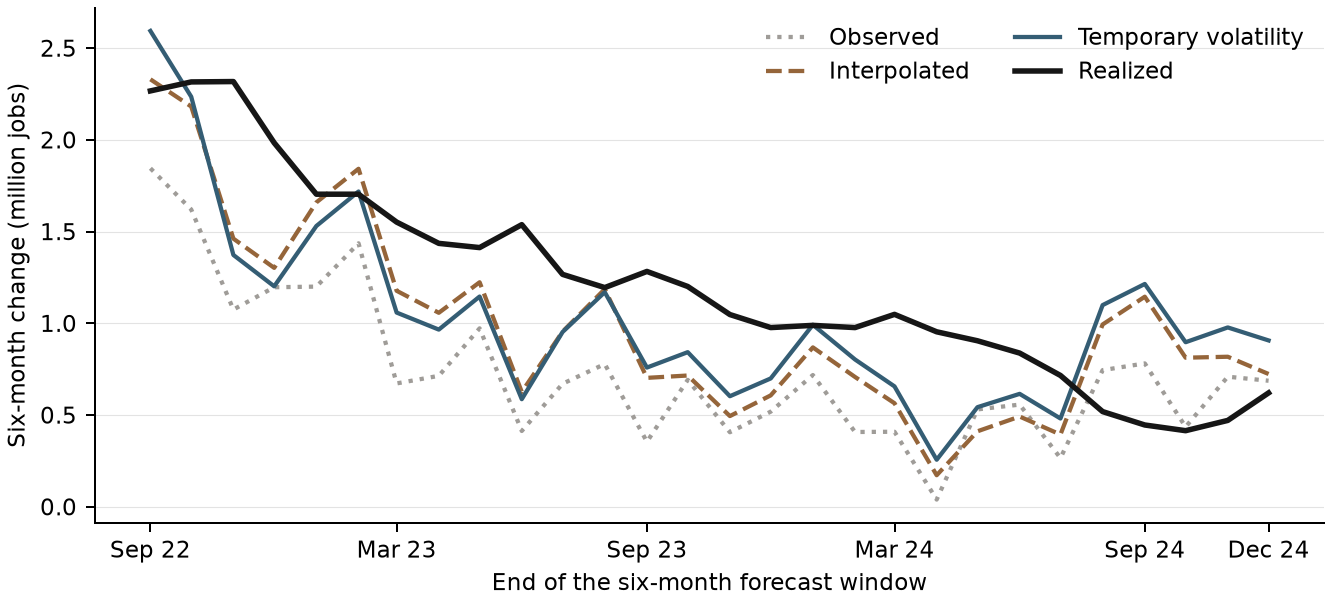

In [4]:
scores = score_forecasts(f)
pd.testing.assert_frame_equal(scores, pd.read_csv(res / 'scores.csv'), check_dtype=False, rtol=1e-9)
display(scores.query('sample == "All"')[['treatment','outcome','n','rmse','mae','bias','covered','width']].round(1))
display(Image(filename=str(res / 'figures/payroll_paths.png'), width=670))

## A simple benchmark and the starting observations
Repeat the job gain in the previous six months. This uses one observed change and has no fitted parameters. For interpolation, compare the primary observed starting lags with a forecast initialized using the smoothed series.

In [5]:
rule = pd.read_csv(res / 'persistence.csv').dropna(subset=['revised'])
display(pd.Series({target: np.sqrt(np.mean((rule.prediction-rule[target])**2))
                   for target in ['revised','first_change_sum']}, name='Repeat previous gain: RMSE').round(1))
own = pd.read_csv(res / 'smoothed_state_scores.csv')
display(own.query('sample == "All"')[['treatment','outcome','rmse','coverage','width']].round(2))

revised             596.3
first_change_sum    514.7
Name: Repeat previous gain: RMSE, dtype: float64

,treatment,outcome,rmse,coverage,width
0,Interpolated,revised,708.35,0.93,3047.25
1,Interpolated,first_change_sum,863.79,0.96,3047.25


## Do independent six-month windows tell the same story?
Adjacent forecasts overlap by five months. Every sixth origin gives four or five nonoverlapping windows per offset. The six offsets are alternative views of the same episode. A second run changes all simulation seeds.

In [6]:
display(scores.query('outcome == "revised"').pivot(index='sample', columns='treatment', values='rmse').round(1))
repeat = pd.read_csv(res / 'replay_scores.csv')
display(repeat.query('sample == "All"')[['treatment','outcome','rmse']].round(1))

treatment,Interpolated,Observed,Temporary volatility
sample,,,
All,459.3,611.4,473.2
Offset 0,490.8,683.4,523.4
Offset 1,482.9,648.2,463.6
Offset 2,536.4,685.1,556.8
Offset 3,559.1,659.9,587.3
Offset 4,233.1,470.4,214.3
Offset 5,281.7,393.8,303.4


,treatment,outcome,rmse
0,Observed,revised,608.9
1,Observed,first_change_sum,874.6
2,Interpolated,revised,459.9
3,Interpolated,first_change_sum,694.9
4,Temporary volatility,revised,473.1
5,Temporary volatility,first_change_sum,662.0


## Retrospective crisis scenario
These calculations look back at February 2020 with parameters learned through March 2022. Allowing the future shock variance to rise shows how much room the fitted distribution makes for the observed contraction. These two rows are excluded from the accuracy tables.

In [7]:
stress = pd.read_csv(res / 'retrospective_scenario.csv')
display(stress[['parameter_cutoff','future_covariance','p05','median','p95','observed_gain']].round(1))

,parameter_cutoff,future_covariance,p05,median,p95,observed_gain
0,2022-03,Constant,-642.6,856.5,2379.1,-11472
1,2022-03,Scaled,-11714.7,856.8,14560.0,-11472


## Separate check on signal extraction
A Kalman filter and direct Gaussian conditioning recover the same terminal signal from 200 noisy observations. The historical BVAR estimates curvature and persistence from economic data. This exercise uses known dynamics.

In [8]:
signal = json.loads((res / 'signal.json').read_text())
display(pd.Series({k: signal[k] for k in ['n','last_message','q25','median','q75','variance','max_conditioning_difference']}))
assert signal['max_conditioning_difference'] < 1e-9

n                              2.000000e+02
last_message                  -2.675300e+00
q25                           -2.719556e+00
median                        -2.146847e+00
q75                           -1.574137e+00
variance                       7.209716e-01
max_conditioning_difference    2.220446e-15
dtype: float64

Across the 28 dates, smoothing produced the lowest revised-level error. The volatility model performed best among the three BVARs against the first-announcement sum, and repeating the preceding gain did better still on that measure. Every six-month outcome was positive. [Executive brief](../docs/executive_summary.pdf) · [Research report](../docs/payroll_after_shocks.pdf)